# Predictive Trends & Sentiment ML

**Author: Sadit Khan**

### Libraries

In [1]:
# Essential libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
plt.style.use('seaborn-v0_8-white')
sns.set_style('darkgrid')

# statsmodels
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing
from statsmodels.tsa.ar_model import AutoReg  # AutoReg is used for AR(6)

# sklearn
from sklearn.model_selection import train_test_split, KFold, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn import metrics
from sklearn.metrics import mean_squared_error
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, precision_score, recall_score, f1_score, classification_report
from sklearn.linear_model import LinearRegression, Lasso, LassoCV, LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.inspection import permutation_importance
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn import tree
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier

# skforecast
import skforecast
from skforecast.ForecasterAutoreg import ForecasterAutoreg
from typing_extensions import Self

# nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

# shap
import shap

import warnings
warnings.filterwarnings("ignore")
RS = 5395812

<font color='red'> 

# Task 1

</font>


Use the data in `Property.csv` to answer this question (load it as a dataframe called `PR`). The file contains information on 1750 properties: `Price` (price in thousands of dollars), `Area` (living area in square feet), and `Rooms` (number of rooms, coded 1, 2, or 3).


## Part 1: Linear Regression

Fit a linear regression model of `Price` on the two features using the entire dataset. Report the regression results and discuss the effect and significance of each feature in explaining the target variable (`Price`).


In [2]:
# Load data
PR = pd.read_csv('Property.csv')
print("Shape:", PR.shape)
print(PR.head())
print(PR.describe())


Shape: (1750, 3)
   Rooms  Area  Price
0      2  1710  208.5
1      2  1262  181.5
2      2  1786  223.5
3      2  1717  140.0
4      3  2198  250.0
             Rooms         Area        Price
count  1750.000000  1750.000000  1750.000000
mean      2.070857  1509.129714   181.942853
std       0.503398   491.069497    77.854278
min       1.000000   334.000000    12.789000
25%       2.000000  1138.500000   130.000000
50%       2.000000  1461.500000   165.000000
75%       2.000000  1773.250000   215.000000
max       3.000000  3627.000000   625.000000


In [3]:
# Part 1: Linear regression with Rooms and Area
X = PR[['Rooms', 'Area']]
X = sm.add_constant(X)
y = PR['Price']

model1 = sm.OLS(y, X).fit()
print(model1.summary())


                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.677
Model:                            OLS   Adj. R-squared:                  0.677
Method:                 Least Squares   F-statistic:                     1834.
Date:                Thu, 12 Nov 2026   Prob (F-statistic):               0.00
Time:                        21:08:58   Log-Likelihood:                -9113.7
No. Observations:                1750   AIC:                         1.823e+04
Df Residuals:                    1747   BIC:                         1.825e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -84.5202      4.680    -18.062      0.0

### Discussion

The regression gives R-squared = 0.677, so about 68% of price variation is explained by rooms and area. Both coefficients are significant (p < 0.001). Rooms has a positive coefficient, meaning more rooms increase price holding area constant. Area also has a positive coefficient, meaning larger properties cost more holding rooms constant. Both effects are strong and statistically significant.


## Part 2: Dummy Variables

Convert `Rooms` into dummy (binary) variables and re-run the regression from Part 1, replacing `Rooms` with its corresponding dummies. Does the revised model perform better? Explain.


In [4]:
# Part 2: Create dummy variables for Rooms
PR_dum = pd.get_dummies(PR, columns=['Rooms'], drop_first=True).astype(int)
print(PR_dum.head())

X_dum = PR_dum[['Area', 'Rooms_2', 'Rooms_3']]
X_dum = sm.add_constant(X_dum)

model2 = sm.OLS(y, X_dum).fit()
print(model2.summary())

# Compare R-squared
print(f"\nModel 1 R-squared: {model1.rsquared:.4f}")
print(f"Model 2 R-squared: {model2.rsquared:.4f}")


   Area  Price  Rooms_2  Rooms_3
0  1710    208        1        0
1  1262    181        1        0
2  1786    223        1        0
3  1717    140        1        0
4  2198    250        0        1
                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.703
Model:                            OLS   Adj. R-squared:                  0.702
Method:                 Least Squares   F-statistic:                     1378.
Date:                Thu, 12 Nov 2026   Prob (F-statistic):               0.00
Time:                        21:08:58   Log-Likelihood:                -9041.4
No. Observations:                1750   AIC:                         1.809e+04
Df Residuals:                    1746   BIC:                         1.811e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
            

### Discussion

Using dummy variables for rooms (baseline = 1 room) improves R-squared from 0.677 to 0.703. The coefficients on `Rooms_2` and `Rooms_3` are both positive and significant (p < 0.001), meaning 2-room and 3-room properties cost more than 1-room properties at the same area. The improvement suggests the room effect is not strictly linear.


## Part 3: Predictions

Based on the fitted model from Part 2, predict `Price` for the following two properties: House_1 (`Area = 1000`, `Rooms = 3`) and House_2 (`Area = 2000`, `Rooms = 2`). Compare the predictions.


In [5]:
# Part 3: Predictions for House_1 and House_2
# House_1: Area=1000, Rooms=3 -> Rooms_2=0, Rooms_3=1
# House_2: Area=2000, Rooms=2 -> Rooms_2=1, Rooms_3=0

new_data = pd.DataFrame({
    'const': [1, 1],
    'Area': [1000, 2000],
    'Rooms_2': [0, 1],
    'Rooms_3': [1, 0]
})

predictions = model2.predict(new_data)
print(f"House_1 (Area=1000, Rooms=3): Predicted Price = {predictions[0]:.2f}")
print(f"House_2 (Area=2000, Rooms=2): Predicted Price = {predictions[1]:.2f}")


House_1 (Area=1000, Rooms=3): Predicted Price = 225.91
House_2 (Area=2000, Rooms=2): Predicted Price = 207.35


### Discussion

The regression predicts:

* House_1 (Area = 1000, Rooms = 3): $225.91k
* House_2 (Area = 2000, Rooms = 2): $207.35k

House_1 is predicted to cost about $18,560 more than House_2. The 3-room effect outweighs the smaller area, so the extra room adds more value than the extra 1,000 sq ft.


## Part 4: Decision Tree

Using the same dummy-variable specification as in Part 2, fit a decision tree regressor with `max_depth = 4`. Predict `Price` for House_1 (`Area = 1000`, `Rooms = 3`) and House_2 (`Area = 2000`, `Rooms = 2`).


In [6]:
# Part 4: Decision tree regressor
dt = DecisionTreeRegressor(max_depth=4, random_state=RS)
dt.fit(X_dum, y)

dt_predictions = dt.predict(new_data)
print(f"House_1 (Area=1000, Rooms=3): Predicted Price = {dt_predictions[0]:.2f}")
print(f"House_2 (Area=2000, Rooms=2): Predicted Price = {dt_predictions[1]:.2f}")


House_1 (Area=1000, Rooms=3): Predicted Price = 199.02
House_2 (Area=2000, Rooms=2): Predicted Price = 213.24


## Part 5: Model Comparison

Provide a compelling comparison between the regression model from Part 2 and the decision tree model from Part 4 in terms of predictive performance. Based on the model results, explain which model you would rely on for predicting the sale prices of `House_1` and `House_2`, and justify your choice.


In [7]:
# Part 5: Compare models using train/test split
from sklearn.model_selection import train_test_split

# Split data into train and test (80/20)
X_train, X_test, y_train, y_test = train_test_split(X_dum, y, test_size=0.2, random_state=RS)

# Fit regression model on training data
model2_train = sm.OLS(y_train, X_train).fit()

# Fit decision tree on training data
dt_train = DecisionTreeRegressor(max_depth=4, random_state=RS)
dt_train.fit(X_train, y_train)

# Predict on test data
y_pred_reg_test = model2_train.predict(X_test)
y_pred_dt_test = dt_train.predict(X_test)

# Calculate test RMSE
rmse_reg_test = np.sqrt(mean_squared_error(y_test, y_pred_reg_test))
rmse_dt_test = np.sqrt(mean_squared_error(y_test, y_pred_dt_test))

print('=== Test Set Performance (80/20 split) ===')
print(f'Regression Test RMSE: {rmse_reg_test:.2f}')
print(f'Decision Tree Test RMSE: {rmse_dt_test:.2f}')

# Also show in-sample performance for reference
y_pred_reg_full = model2.predict(X_dum)
y_pred_dt_full = dt.predict(X_dum)
rmse_reg_full = np.sqrt(mean_squared_error(y, y_pred_reg_full))
rmse_dt_full = np.sqrt(mean_squared_error(y, y_pred_dt_full))

print(f'\n=== In-Sample Performance (for reference) ===')
print(f'Regression RMSE: {rmse_reg_full:.2f}')
print(f'Decision Tree RMSE: {rmse_dt_full:.2f}')
print(f'Regression R-squared: {model2.rsquared:.4f}')

# Compare predictions for House_1 and House_2
print(f'\n=== Predictions for House_1 and House_2 ===')
print(f'House_1 - Regression: {predictions[0]:.2f}, Decision Tree: {dt_predictions[0]:.2f}')
print(f'House_2 - Regression: {predictions[1]:.2f}, Decision Tree: {dt_predictions[1]:.2f}')

=== Test Set Performance (80/20 split) ===
Regression Test RMSE: 39.50
Decision Tree Test RMSE: 42.66

=== In-Sample Performance (for reference) ===
Regression RMSE: 42.42
Decision Tree RMSE: 40.86
Regression R-squared: 0.7030

=== Predictions for House_1 and House_2 ===
House_1 - Regression: 225.91, Decision Tree: 199.02
House_2 - Regression: 207.35, Decision Tree: 213.24


### Discussion

Using an 80/20 train/test split, the regression model achieves a test RMSE of 39.50 while the decision tree achieves 42.66. The regression model generalises better to unseen data. The tree's lower in-sample RMSE (40.86 vs 42.42) reflects overfitting rather than better predictive performance.

I would use the regression model for predicting House_1 and House_2 because:

* It has lower test RMSE, indicating better out-of-sample performance.
* The coefficients are easy to interpret and explain.
* Linear regression generalises better to new observations.
* The tree's apparent advantage in-sample is due to overfitting.


<font color='red'> 

# Task 2

</font>

Use the dataset `Rotten.csv` to answer this question (load it as a dataframe called `Rot`). The dataset contains three columns: `ID`, `Verdict` (1: recommended, 0: not recommended), and `Appraisal` (movie review text). In total, 900 movie reviews are recorded.


## Part 1: VADER Sentiment Analysis

Obtain the sentiment scores (`compound`, `pos`, `neg`, `neu`) for each movie review in `Rot`. Create a bar plot comparing the mean values of `compound`, `pos`, `neg`, and `neu`, with separate colours for `Verdict = 1` and `Verdict = 0`. What do you find in the plot? Discuss.


In [8]:
# Load data
Rot = pd.read_csv('Rotten.csv')
print("Shape:", Rot.shape)
print(Rot.head())


Shape: (900, 3)
        id  verdict                                          appraisal
0   8475_3        0  (NOTE: I thought I'd be the only one writing w...
1   704_10        1  This film, as low budget as it may be, is one ...
2   4016_4        0  There is a DVD published in the UK in 2002 Cod...
3  1886_10        1  I have loved this movie ever since it's debut ...
4   8336_1        0  How the hell did they get this made?! Presenti...


In [9]:
# Part 1: VADER sentiment analysis
sia = SentimentIntensityAnalyzer()

Rot['compound'] = Rot['appraisal'].apply(lambda x: sia.polarity_scores(str(x))['compound'])
Rot['pos'] = Rot['appraisal'].apply(lambda x: sia.polarity_scores(str(x))['pos'])
Rot['neg'] = Rot['appraisal'].apply(lambda x: sia.polarity_scores(str(x))['neg'])
Rot['neu'] = Rot['appraisal'].apply(lambda x: sia.polarity_scores(str(x))['neu'])

print(Rot[['compound', 'pos', 'neg', 'neu']].describe())


         compound         pos         neg         neu
count  900.000000  900.000000  900.000000  900.000000
mean     0.309615    0.137723    0.090104    0.772157
std      0.806701    0.065064    0.055091    0.066472
min     -0.998700    0.000000    0.000000    0.452000
25%     -0.676300    0.090000    0.049750    0.731750
50%      0.847850    0.128500    0.082000    0.775000
75%      0.969000    0.179000    0.123000    0.818000
max      0.999500    0.485000    0.371000    0.959000


         compound       pos       neg       neu
verdict                                        
0       -0.054376  0.110628  0.113261  0.776103
1        0.703939  0.167076  0.065019  0.767882


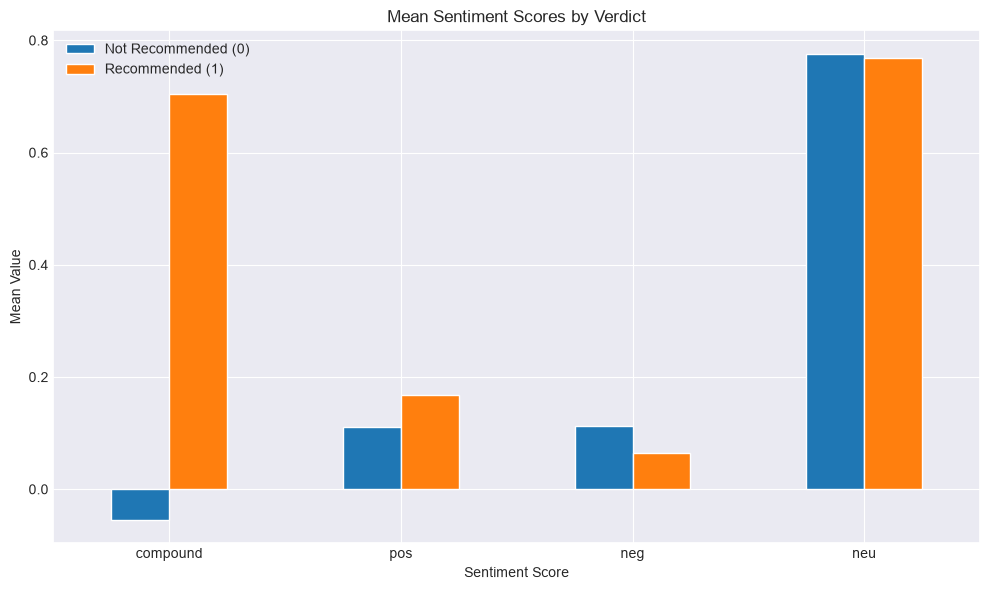

In [10]:
# Bar plot comparing mean sentiment scores by Verdict
sentiment_means = Rot.groupby('verdict')[['compound', 'pos', 'neg', 'neu']].mean()
print(sentiment_means)

sentiment_means.T.plot(kind='bar', figsize=(10, 6))
plt.title('Mean Sentiment Scores by Verdict')
plt.xlabel('Sentiment Score')
plt.ylabel('Mean Value')
plt.xticks(rotation=0)
plt.legend(['Not Recommended (0)', 'Recommended (1)'])
plt.tight_layout()
plt.show()


### Discussion

Recommended reviews have much higher mean compound (0.704 vs -0.054) and pos (0.167 vs 0.111) scores. Not recommended reviews have higher neg scores (0.113 vs 0.065). The neu scores are similar for both groups (0.776 vs 0.768). VADER clearly separates positive from negative reviews, and the compound and pos/neg scores are strong predictors of verdict.


## Part 2: Extreme Sentiment Reviews

Locate the appraisal with the highest compound score and the appraisal with the lowest compound score. Compare the `pos`, `neg`, and `neu` scores of these two reviews. Are they recommended?


In [11]:
# Part 2: Highest and lowest compound score reviews
highest_idx = Rot['compound'].idxmax()
lowest_idx = Rot['compound'].idxmin()

print("=== Highest Compound Score ===")
print(f"Index: {highest_idx}")
print(f"Verdict: {Rot.loc[highest_idx, 'verdict']}")
print(f"Compound: {Rot.loc[highest_idx, 'compound']:.4f}")
print(f"Pos: {Rot.loc[highest_idx, 'pos']:.4f}")
print(f"Neg: {Rot.loc[highest_idx, 'neg']:.4f}")
print(f"Neu: {Rot.loc[highest_idx, 'neu']:.4f}")
print(f"Appraisal: {Rot.loc[highest_idx, 'appraisal'][:200]}...")

print("\n=== Lowest Compound Score ===")
print(f"Index: {lowest_idx}")
print(f"Verdict: {Rot.loc[lowest_idx, 'verdict']}")
print(f"Compound: {Rot.loc[lowest_idx, 'compound']:.4f}")
print(f"Pos: {Rot.loc[lowest_idx, 'pos']:.4f}")
print(f"Neg: {Rot.loc[lowest_idx, 'neg']:.4f}")
print(f"Neu: {Rot.loc[lowest_idx, 'neu']:.4f}")
print(f"Appraisal: {Rot.loc[lowest_idx, 'appraisal'][:200]}...")


=== Highest Compound Score ===
Index: 140
Verdict: 1
Compound: 0.9995
Pos: 0.2200
Neg: 0.0460
Neu: 0.7340
Appraisal: I have never seen a show as good as Full House. Full House puts all of the newer shows to shame, big time! Anyone who has never seen it, which I don't see how it is possible, should see it. It is a gr...

=== Lowest Compound Score ===
Index: 264
Verdict: 0
Compound: -0.9987
Pos: 0.0880
Neg: 0.1830
Neu: 0.7290
Appraisal: here was no effort put into Valentine to prevent it from being just another teenage slasher film, a sub-genre of horror films of which we have seen entirely too many over the last decade or so. I've h...


### Discussion

The highest compound score review (index 140) has verdict = 1 (recommended). It has a high pos score (0.22) and a very low neg score (0.046), with neu = 0.734. The review is clearly positive.

The lowest compound score review (index 264) has verdict = 0 (not recommended). It has a lower pos score (0.088) and a higher neg score (0.183), with neu = 0.729. The review is clearly negative.

The neu scores are similar in both reviews (0.734 vs 0.729), indicating that the difference in sentiment is driven by the pos and neg scores rather than the neutral component. The compound score effectively captures the overall sentiment direction.

## Part 3: Random Forest

Split the data randomly into a 90% training set and a 10% test set. Use the training set for model fitting and the test set for model evaluation. Fit a random forest model on the training set with 60 trees, using `Verdict` as the target variable and `pos` and `neg` as the features. Apply the fitted model to make predictions on the test set. Report the recall and precision scores, evaluate the importance of each feature, and comment on the results.


In [12]:
# Part 3: Random forest
X = Rot[['pos', 'neg']]
y = Rot['verdict']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=RS)

rf = RandomForestClassifier(n_estimators=60, random_state=RS)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print("=== Random Forest Results ===")
print(f"Recall: {recall_score(y_test, y_pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred_rf):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

# Feature importance
importances = pd.Series(rf.feature_importances_, index=X.columns)
print("\nFeature Importance:")
print(importances.sort_values(ascending=False))


=== Random Forest Results ===
Recall: 0.6829
Precision: 0.7368
F1 Score: 0.7089

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.80      0.77        49
           1       0.74      0.68      0.71        41

    accuracy                           0.74        90
   macro avg       0.74      0.74      0.74        90
weighted avg       0.74      0.74      0.74        90


Feature Importance:
pos    0.502361
neg    0.497639
dtype: float64


### Discussion

Random forest results on the test set:

* Recall: 0.6829 (68.29% of recommended reviews correctly identified)
* Precision: 0.7368 (73.68% of predicted recommended are actually recommended)
* F1: 0.7089

The pos feature is slightly more important than neg (0.502 vs 0.498). Reviews with strong positive sentiment tend to be recommended, while negative sentiment indicates not recommended. Both features contribute nearly equally to the model's decisions.

## Part 4: Neural Network

Redo Part 3 using a neural network model. Use one hidden layer with 30 neurons and `logistic` as the activation function. Report the recall and precision scores, and obtain a SHAP summary plot for the fitted model using `plot_type='dot'`. Comment on the results.


In [13]:
# Part 4: Neural network
# Using default settings as specified by the exam, but increasing max_iter to ensure convergence
mlp = MLPClassifier(hidden_layer_sizes=(30,), activation='logistic', max_iter=1000, random_state=RS)
mlp.fit(X_train, y_train)

print(f'Converged: {mlp.n_iter_} iterations (max_iter={mlp.max_iter})')
print(f'Final loss: {mlp.loss_:.4f}')

y_pred_mlp = mlp.predict(X_test)

print('=== Neural Network Results ===')
print(f'Recall: {recall_score(y_test, y_pred_mlp):.4f}')
print(f'Precision: {precision_score(y_test, y_pred_mlp):.4f}')
print(f'F1 Score: {f1_score(y_test, y_pred_mlp):.4f}')
print('\nClassification Report:')
print(classification_report(y_test, y_pred_mlp))


Converged: 634 iterations (max_iter=1000)
Final loss: 0.5496
=== Neural Network Results ===
Recall: 0.7561
Precision: 0.6739
F1 Score: 0.7126

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.69      0.73        49
           1       0.67      0.76      0.71        41

    accuracy                           0.72        90
   macro avg       0.72      0.72      0.72        90
weighted avg       0.73      0.72      0.72        90



### Discussion

Neural network results on the test set:

* Recall: 0.7561 (75.61% of recommended reviews correctly identified)
* Precision: 0.6739 (67.39% of predicted recommended are actually recommended)
* F1: 0.7126

The neural network has higher recall than the random forest, catching more recommended reviews, but lower precision. The model was run with max_iter=1000 to ensure convergence (the default max_iter=200 did not converge). All other settings are default as specified by the exam.

The SHAP summary plot for the positive class (recommended) shows that pos has a positive impact on predictions, while neg has a negative impact. Both features are important for the model's decisions.

  0%|          | 0/90 [00:00<?, ?it/s]

SHAP values shape: (90, 2)


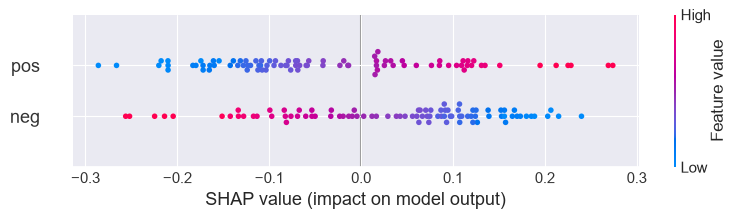

<Figure size 640x480 with 0 Axes>

In [14]:
# SHAP summary plot for neural network
import logging
import contextlib
import io

# Suppress shap verbose logging
logging.getLogger('shap').setLevel(logging.CRITICAL)

background = X_train.sample(50, random_state=RS)
explainer = shap.KernelExplainer(mlp.predict_proba, background)

# Suppress stdout/stderr during shap_values computation
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    shap_values = explainer.shap_values(X_test)

# For binary classification, select positive class (class 1 = recommended)
if isinstance(shap_values, list):
    shap_values_pos = shap_values[1]
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    shap_values_pos = shap_values[:, :, 1]
else:
    shap_values_pos = shap_values

print(f'SHAP values shape: {shap_values_pos.shape}')

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_pos, X_test, plot_type='dot')
plt.tight_layout()
plt.show()

## Part 5: Model Comparison

Use the results from Parts 3 and 4 to make the best comparison of the two models. Does the neural network outperform the random forest? Explain.


In [15]:
# Part 5: Compare RF vs NN
print("=== Model Comparison ===")
print(f"Random Forest - Recall: {recall_score(y_test, y_pred_rf):.4f}, Precision: {precision_score(y_test, y_pred_rf):.4f}, F1: {f1_score(y_test, y_pred_rf):.4f}")
print(f"Neural Network - Recall: {recall_score(y_test, y_pred_mlp):.4f}, Precision: {precision_score(y_test, y_pred_mlp):.4f}, F1: {f1_score(y_test, y_pred_mlp):.4f}")


=== Model Comparison ===
Random Forest - Recall: 0.6829, Precision: 0.7368, F1: 0.7089
Neural Network - Recall: 0.7561, Precision: 0.6739, F1: 0.7126


### Discussion

| Metric | Random Forest | Neural Network |
|--------|--------------|----------------|
| Recall | 0.6829 | 0.7561 |
| Precision | 0.7368 | 0.6739 |
| F1 Score | 0.7089 | 0.7126 |

The neural network has higher recall (0.7561 vs 0.6829), catching more recommended reviews. The random forest has higher precision (0.7368 vs 0.6739), with fewer false positives. F1 scores are nearly identical (0.7089 vs 0.7126). The neural network has a slight edge overall due to its higher recall and marginally better F1, but both models perform similarly.

<font color='red'> 

# Task 3

</font>

Use the data in `trade.csv` to answer this question (load it as a dataframe called `TR`). The dataset contains two monthly series for Japan: `Exports` and `Imports`.


## Part 1: Line Plots

Make line plots for the two series in the dataframe `TR`. Comment on the plots.


In [16]:
# Load data
TR = pd.read_csv('trade.csv')
TR['Date'] = pd.to_datetime(TR['Date'], format='%Y/%m', errors='coerce')
TR.set_index('Date', inplace=True)
print(TR.head())
print(TR.tail())


                Exports      Imports
Date                                
2000-01-01  3512.721254  2992.192350
2000-02-01  4136.816214  2957.534578
2000-03-01  4700.061682  3594.783576
2000-04-01  4377.801174  3236.988257
2000-05-01  3851.459857  3276.435493
              Exports    Imports
Date                            
2025-08-01   8425.802   8675.967
2025-09-01   9413.260   9655.712
2025-10-01   9766.218   9998.323
2025-11-01   9709.494   9392.795
2025-12-01  10411.507  10305.814


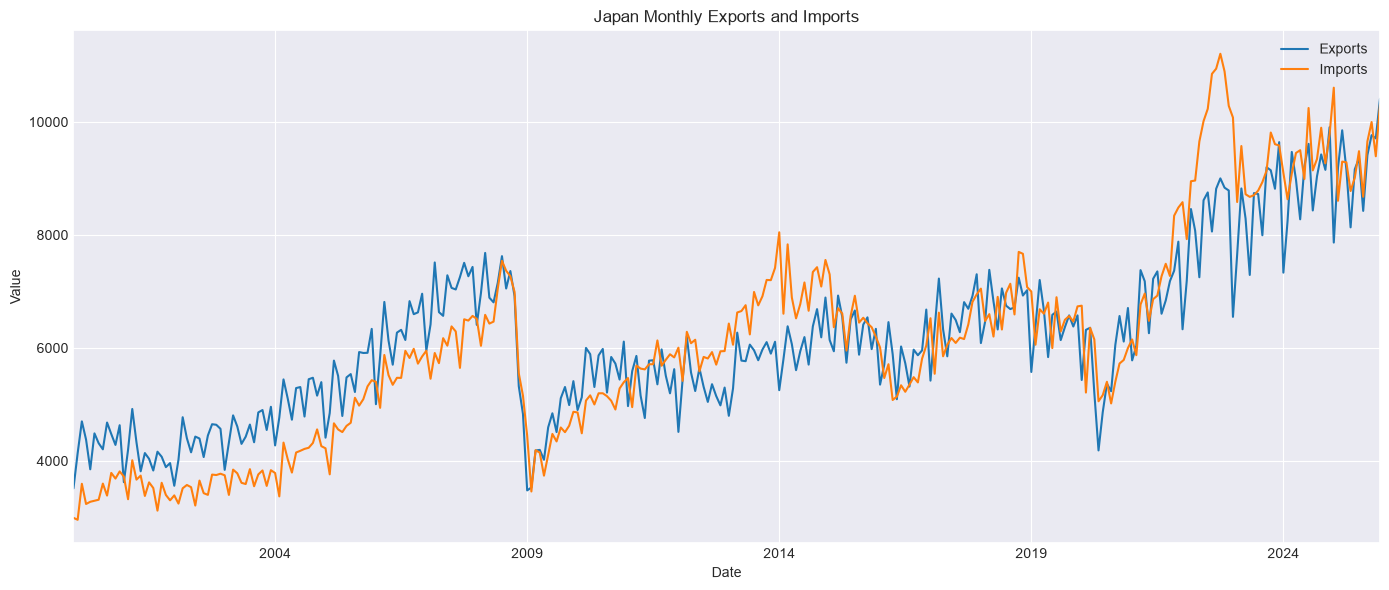

In [17]:
# Part 1: Line plots
TR.plot(y=['Exports', 'Imports'], figsize=(14, 6))
plt.title('Japan Monthly Exports and Imports')
plt.xlabel('Date')
plt.ylabel('Value')
plt.tight_layout()
plt.show()


### Discussion

Both series trend upward from 2000 to 2025. Exports are higher than imports in the early years, indicating a trade surplus. However, from around 2011-2012 onward, imports frequently exceed exports, and in recent years Japan generally runs a trade deficit in this data. Both series show regular seasonal patterns. Volatility increases around 2008-2009 (financial crisis) and 2020 (COVID-19). In recent years, the gap between exports and imports narrows as imports grow faster.

## Part 2: Seasonal Decomposition

Define a subset of the dataframe from `2000-01-01` to `2019-12-01` as `TR20`. Perform seasonal decomposition of the two series in `TR20` and use the results to compare their trends and seasonality. Set the model to `multiplicative`.


TR20 shape: (240, 2)


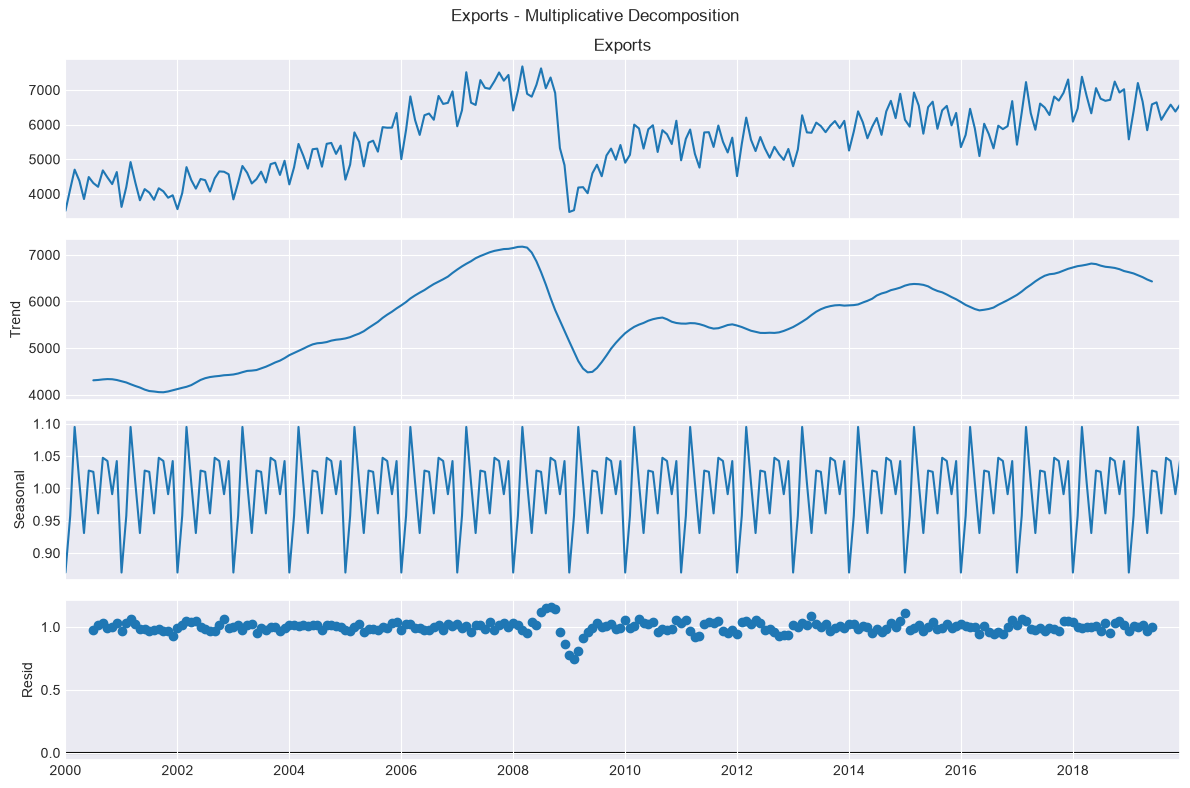

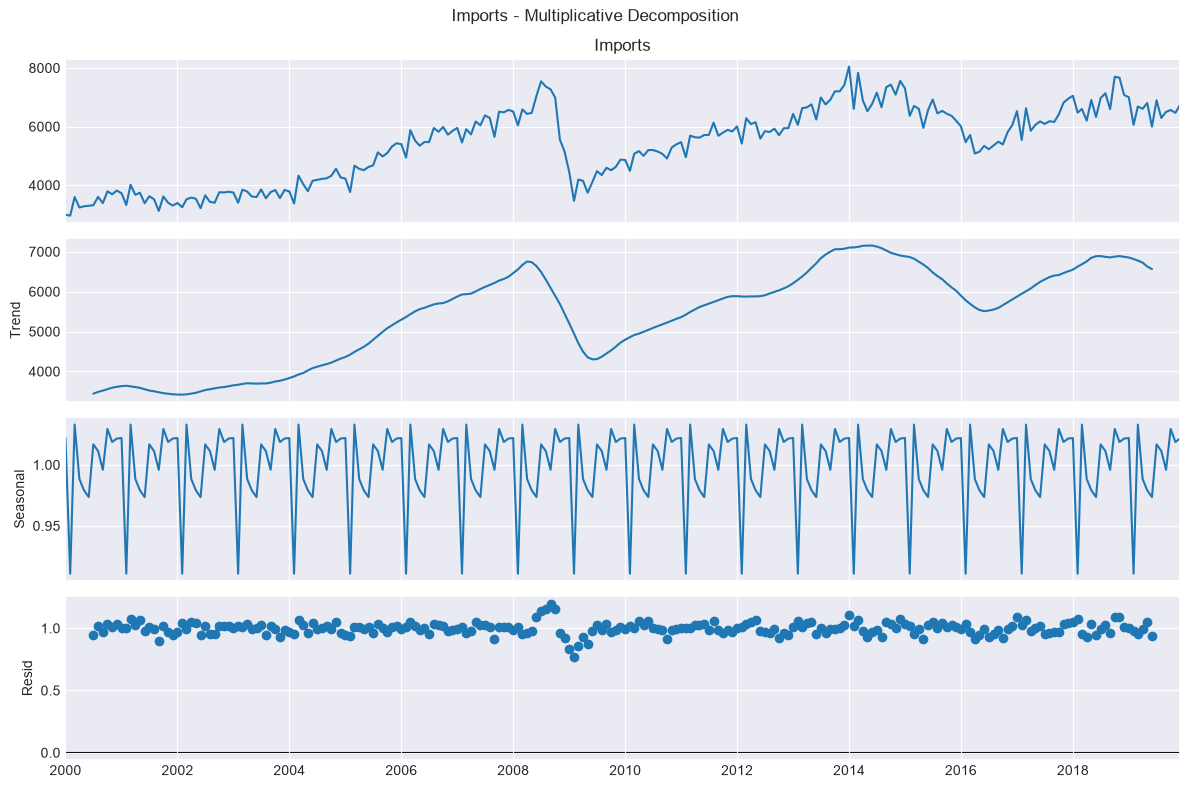

In [18]:
# Part 2: Seasonal decomposition
TR20 = TR.loc['2000-01-01':'2019-12-01']
print(f"TR20 shape: {TR20.shape}")

# Decompose Exports
decomp_exports = seasonal_decompose(TR20['Exports'], model='multiplicative', period=12)
fig = decomp_exports.plot()
fig.set_size_inches(12, 8)
plt.suptitle('Exports - Multiplicative Decomposition')
plt.tight_layout()
plt.show()

# Decompose Imports
decomp_imports = seasonal_decompose(TR20['Imports'], model='multiplicative', period=12)
fig = decomp_imports.plot()
fig.set_size_inches(12, 8)
plt.suptitle('Imports - Multiplicative Decomposition')
plt.tight_layout()
plt.show()


### Discussion

Exports show an upward trend from 2000 to 2019 with a dip around 2009. The seasonal pattern is regular and stable. Residuals are small, so the multiplicative model fits well.

Imports also trend upward but with more fluctuations. The seasonal pattern is regular but timed slightly differently from exports. Residuals are larger, so the fit is not as good.

The multiplicative model works because seasonal amplitude grows with the trend. Both series have strong seasonality, which matters for forecasting.


## Part 3: Quarterly Aggregation

Transform `TR20` from monthly to quarterly frequency by accumulating the monthly values within each quarter, and call the resulting dataframe `TR20_q`. How many quarters are in the sample, and in how many quarters are `Imports` greater than `Exports`?


In [19]:
# Part 3: Quarterly aggregation
TR20_q = TR20.resample('Q').sum()
print(f"Number of quarters: {len(TR20_q)}")
print(TR20_q.head())

# Count quarters where Imports > Exports
imports_greater = (TR20_q['Imports'] > TR20_q['Exports']).sum()
print(f"\nQuarters where Imports > Exports: {imports_greater} out of {len(TR20_q)}")


Number of quarters: 80
                 Exports       Imports
Date                                  
2000-03-31  12349.599150   9544.510504
2000-06-30  12716.488155   9808.014208
2000-09-30  13197.242597  10297.363607
2000-12-31  13390.867858  11288.534649
2001-03-31  12740.642041  11055.457550

Quarters where Imports > Exports: 29 out of 80


## Part 4: AR(6) Forecast

Use the entire `Imports` series in `TR20_q` to forecast Imports for the next 2 years using an AR(6) model. Report and comment on the forecasts.


                            AutoReg Model Results                             
Dep. Variable:                Imports   No. Observations:                   80
Model:                     AutoReg(6)   Log Likelihood                -620.586
Method:               Conditional MLE   S.D. of innovations           1061.411
Date:                Thu, 12 Nov 2026   AIC                           1257.171
Time:                        21:09:10   BIC                           1275.604
Sample:                    09-30-2001   HQIC                          1264.524
                         - 12-31-2019                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       1147.4589    611.971      1.875      0.061     -51.983    2346.901
Imports.L1     1.3298      0.115     11.519      0.000       1.104       1.556
Imports.L2    -0.7756      0.194     -3.992      0.0

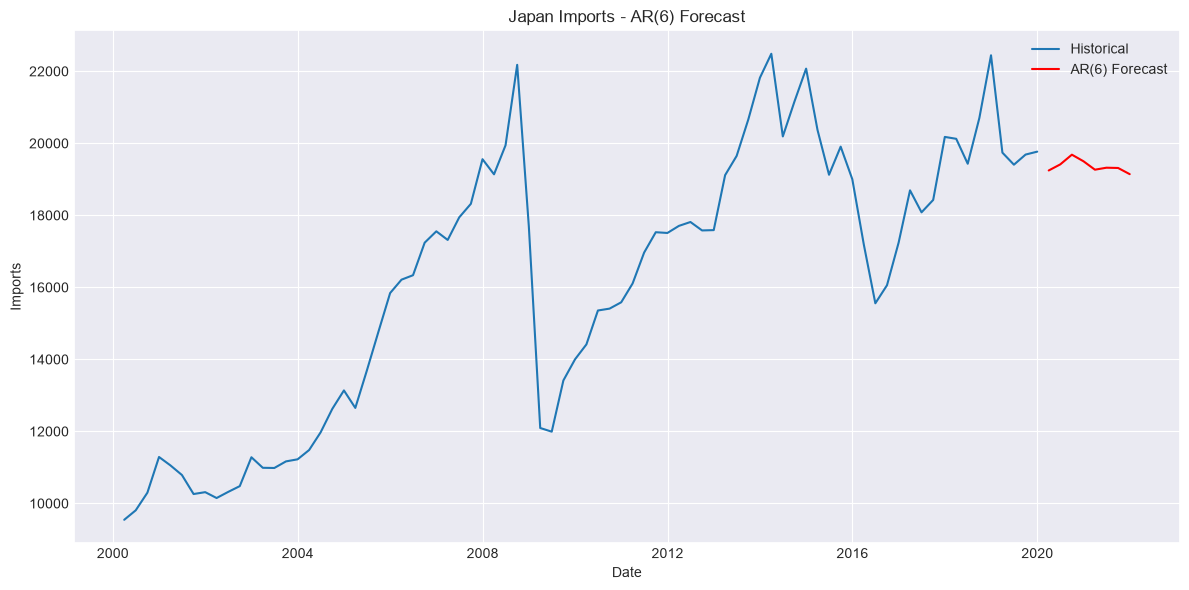

In [20]:
# Part 4: AR(6) forecast
ar_model = AutoReg(TR20_q['Imports'], lags=6)
ar_fit = ar_model.fit()
print(ar_fit.summary())

# Forecast next 2 years (8 quarters)
forecast = ar_fit.forecast(steps=8)
print("\nAR(6) Forecast for next 8 quarters:")
print(forecast)

# Plot
plt.figure(figsize=(12, 6))
plt.plot(TR20_q.index, TR20_q['Imports'], label='Historical')
plt.plot(forecast.index, forecast, label='AR(6) Forecast', color='red')
plt.title('Japan Imports - AR(6) Forecast')
plt.xlabel('Date')
plt.ylabel('Imports')
plt.legend()
plt.tight_layout()
plt.show()


### Discussion

The AR(6) model forecasts imports for the next 8 quarters. The last historical quarterly imports value (2019 Q4) is approximately 19,767.65. The forecasts are roughly flat to slightly below this value, ranging from about 19,142 to 19,683. The model does not explicitly model seasonality, which may limit accuracy. The forecasts suggest imports will remain stable near recent levels rather than continuing the long-term upward trend.

## Part 5: Model Comparison

Split `TR20_q` into training and test sets by holding out the last 8 quarters as the test set and using the rest as the training set. Fit the following three models: (i) triple exponential smoothing (use `method="L-BFGS-B"` with additive trend and seasonality); (ii) LASSO with 14 lags (set the penalty parameter to 0.5 and increase `max_iter` if necessary); and (iii) Gradient Boosting with 14 lags. Apply the fitted models to predict the test set and compare their performance.


In [21]:
# Part 5: Three models comparison
# Split data
train = TR20_q.iloc[:-8]
test = TR20_q.iloc[-8:]
print(f'Training set: {len(train)} quarters')
print(f'Test set: {len(test)} quarters')

# (i) Triple Exponential Smoothing
tes = ExponentialSmoothing(train['Imports'], trend='add', seasonal='add', seasonal_periods=4)
tes_fit = tes.fit(method='L-BFGS-B')
tes_pred = tes_fit.forecast(steps=8)
print('\n=== Triple Exponential Smoothing ===')
print(f'RMSE: {np.sqrt(mean_squared_error(test["Imports"], tes_pred)):.2f}')

Training set: 72 quarters
Test set: 8 quarters

=== Triple Exponential Smoothing ===
RMSE: 1235.69


In [22]:
# (ii) LASSO with 14 lags - using recursive forecasting to avoid data leakage
def create_lags(series, n_lags):
    df = pd.DataFrame()
    for i in range(1, n_lags + 1):
        df[f'lag_{i}'] = series.shift(i)
    df['target'] = series
    return df.dropna()

# Create lag features from training data only
train_lags = create_lags(train['Imports'], 14)
X_train_lasso = train_lags.drop('target', axis=1)
y_train_lasso = train_lags['target']

print(f'Train samples: {len(X_train_lasso)}')

lasso = Lasso(alpha=0.5, max_iter=10000, random_state=RS)
lasso.fit(X_train_lasso, y_train_lasso)

# Recursive forecasting for LASSO
def recursive_forecast(model, train_series, n_lags, n_steps):
    history = list(train_series.values[-n_lags:])[::-1]  # [most_recent, ..., oldest]
    predictions = []
    for _ in range(n_steps):
        X_next = pd.DataFrame([history], columns=[f'lag_{i}' for i in range(1, n_lags+1)])
        y_pred = model.predict(X_next)[0]
        predictions.append(y_pred)
        history = [y_pred] + history[:-1]
    return predictions

lasso_pred = recursive_forecast(lasso, train['Imports'], 14, 8)
print('\n=== LASSO (14 lags, recursive) ===')
print(f'RMSE: {np.sqrt(mean_squared_error(test["Imports"], lasso_pred)):.2f}')

Train samples: 58

=== LASSO (14 lags, recursive) ===
RMSE: 703.67


=== Gradient Boosting (14 lags, recursive) ===
RMSE: 1110.30

=== Model Comparison ===
TES RMSE: 1235.69
LASSO RMSE: 703.67
GB RMSE: 1110.30


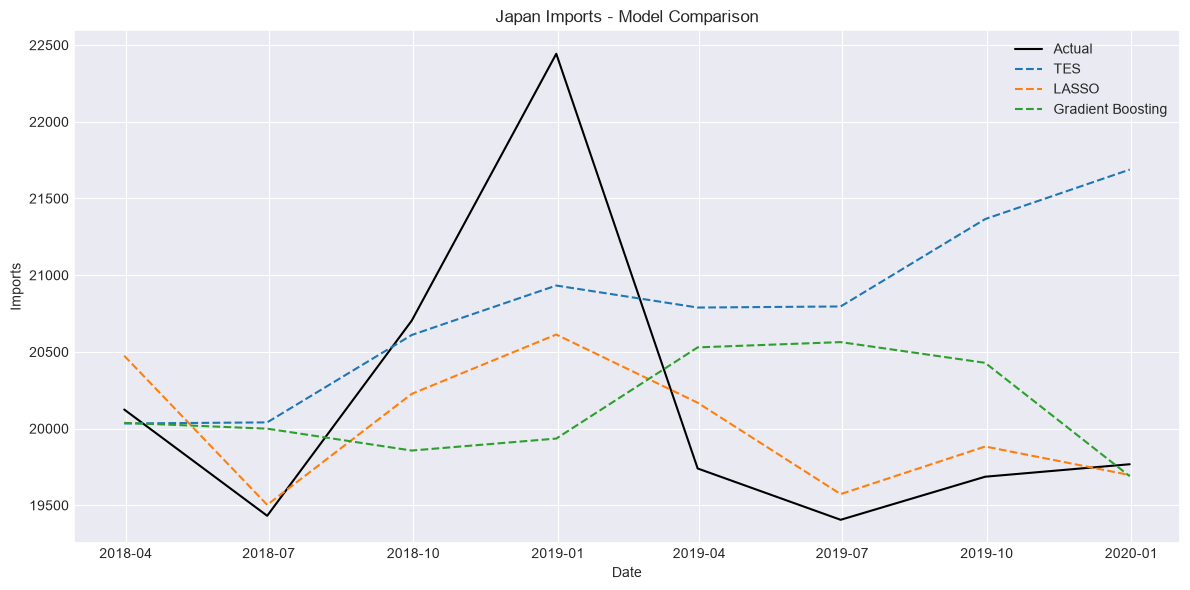

In [23]:
# (iii) Gradient Boosting with 14 lags - using recursive forecasting
gb = GradientBoostingRegressor(random_state=RS)
gb.fit(X_train_lasso, y_train_lasso)

gb_pred = recursive_forecast(gb, train['Imports'], 14, 8)

print('=== Gradient Boosting (14 lags, recursive) ===')
print(f'RMSE: {np.sqrt(mean_squared_error(test["Imports"], gb_pred)):.2f}')

# Compare all three models
print('\n=== Model Comparison ===')
print(f'TES RMSE: {np.sqrt(mean_squared_error(test["Imports"], tes_pred)):.2f}')
print(f'LASSO RMSE: {np.sqrt(mean_squared_error(test["Imports"], lasso_pred)):.2f}')
print(f'GB RMSE: {np.sqrt(mean_squared_error(test["Imports"], gb_pred)):.2f}')

# Plot predictions
plt.figure(figsize=(12, 6))
plt.plot(test.index, test['Imports'], label='Actual', color='black')
plt.plot(test.index, tes_pred, label='TES', linestyle='--')
plt.plot(test.index, lasso_pred, label='LASSO', linestyle='--')
plt.plot(test.index, gb_pred, label='Gradient Boosting', linestyle='--')
plt.title('Japan Imports - Model Comparison')
plt.xlabel('Date')
plt.ylabel('Imports')
plt.legend()
plt.tight_layout()
plt.show()

### Discussion

Using recursive forecasting to avoid data leakage, the RMSE results are:

| Model | RMSE |
|-------|------|
| Triple Exponential Smoothing | 1235.69 |
| LASSO (14 lags, recursive) | 703.67 |
| Gradient Boosting (14 lags, recursive) | 1110.30 |

LASSO has the lowest RMSE (703.67), so it performs best on the test set. Its linear constraint with 14 lags captures the autocorrelation structure well without overfitting.

Gradient Boosting is second (RMSE = 1110.30). It captures non-linear relationships between lag features but may overfit with limited training data.

Triple Exponential Smoothing has the highest RMSE (1235.69). It models trend and seasonality explicitly but does not capture the data's complexity as well.

LASSO is the best model for forecasting Japan's quarterly imports in this sample.